# Chinook Analysis - Simple Version

## Step 1: Connect to the database

In [101]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
conn = sqlite3.connect("Chinook_Sqlite.sqlite")

## Chart 1: Revenue by Country

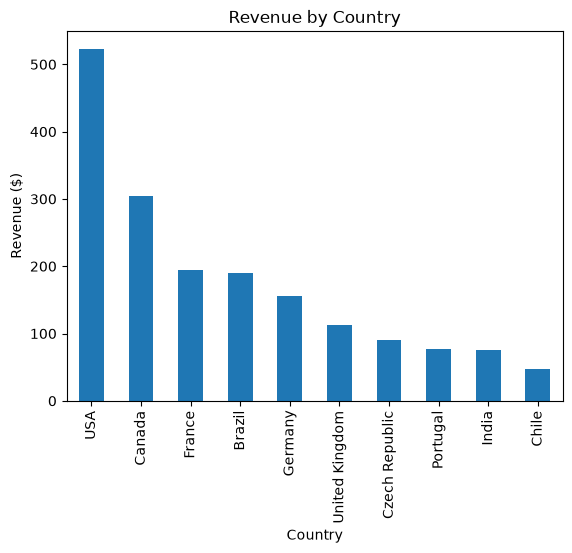

In [102]:
df1 = pd.read_sql_query("""
select BillingCountry, sum(Total) as Revenue from Invoice
group by BillingCountry
order by Revenue desc
limit 10;
""", conn)

df1.plot(kind="bar", x="BillingCountry", y="Revenue", legend=False)
plt.title("Revenue by Country")
plt.ylabel("Revenue ($)")
plt.xlabel("Country")
plt.show()

## Chart 2: Top 10 Customers

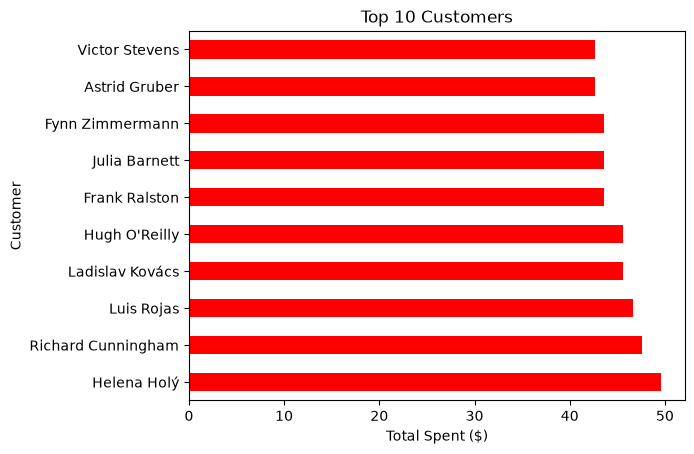

In [103]:
df2 = pd.read_sql_query("""
select c.FirstName || ' ' || c.LastName as Customer, sum(i.Total) as TotalSpent from Customer c
join Invoice i on c.CustomerId = i.CustomerId
group by c.CustomerId
order by TotalSpent desc
limit 10;
""", conn)

df2.plot(kind="barh", x="Customer", y="TotalSpent", legend=False, color="red")
plt.title("Top 10 Customers")
plt.xlabel("Total Spent ($)")
plt.show()

## Chart 3: Revenue by Genre

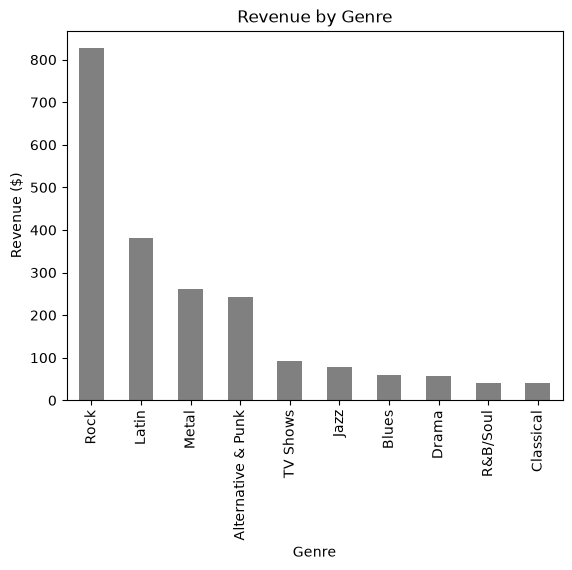

In [104]:
df3 = pd.read_sql_query("""
select g.Name as Genre, sum(il.UnitPrice * il.Quantity) as Revenue from InvoiceLine il
join Track t on il.TrackId = t.TrackId
join Genre g on t.GenreId = g.GenreId
group by g.Name
order by Revenue desc
limit 10;
""", conn)

df3.plot(kind="bar", x="Genre", y="Revenue", legend=False, color="grey")
plt.title("Revenue by Genre")
plt.ylabel("Revenue ($)")
plt.show()

## Chart 4: Top Artists

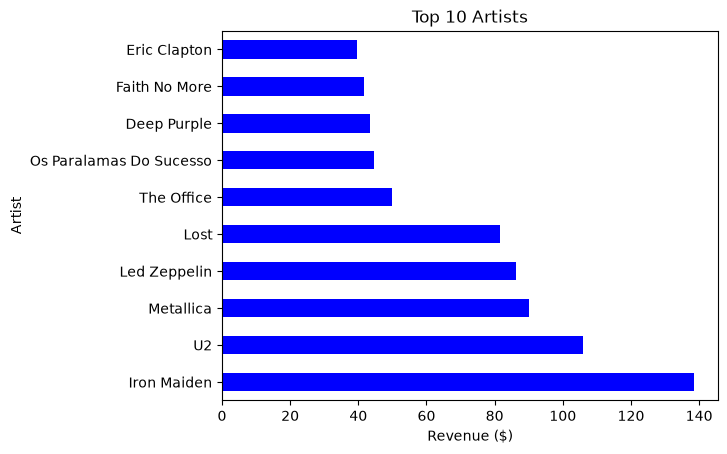

In [105]:
df4 = pd.read_sql_query("""
select ar.Name as Artist, sum(il.UnitPrice * il.Quantity) as Revenue from InvoiceLine il
join Track t on il.TrackId = t.TrackId
join Album al on t.AlbumId = al.AlbumId
join Artist ar on al.ArtistId = ar.ArtistId
group by ar.Name
order by Revenue desc
limit 10;
""", conn)

df4.plot(kind="barh", x="Artist", y="Revenue", legend=False, color="blue")
plt.title("Top 10 Artists")
plt.xlabel("Revenue ($)")
plt.show()

## Chart 5: Sales Trend by Year

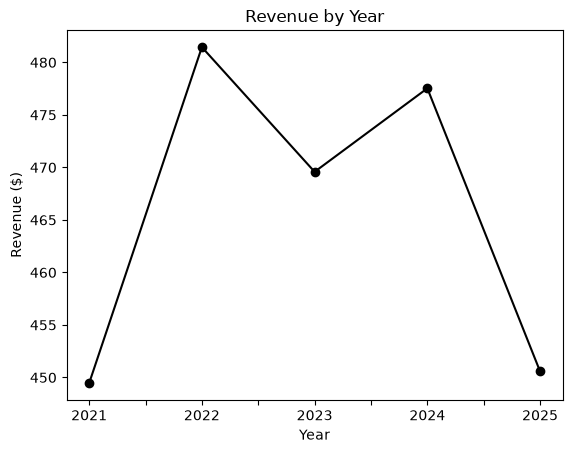

In [106]:
df5 = pd.read_sql_query("""
select strftime('%Y', InvoiceDate) as Year, sum(Total) as Revenue from Invoice
group by Year
order by Year;
""", conn)

df5.plot(kind="line", x="Year", y="Revenue", marker="o", legend=False, color="black")
plt.title("Revenue by Year")
plt.ylabel("Revenue ($)")
plt.show()

## Chart 6: Customers by Country

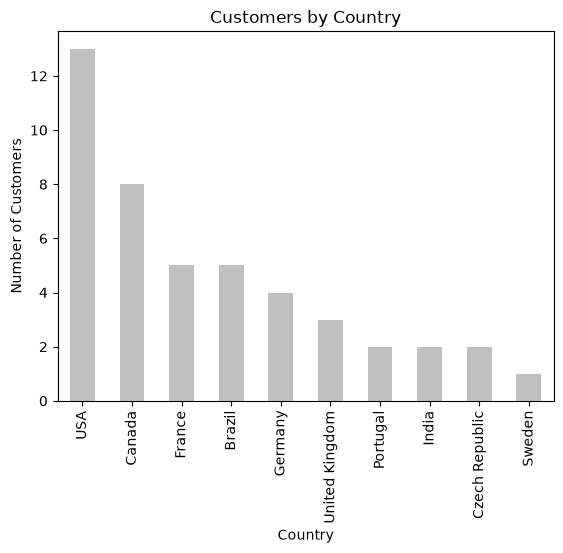

In [107]:
df6 = pd.read_sql_query("""
select Country, count(*) as NumCustomers from Customer
group by Country
order by NumCustomers desc
limit 10;
""", conn)

df6.plot(kind="bar", x="Country", y="NumCustomers", legend=False, color="silver")
plt.title("Customers by Country")
plt.ylabel("Number of Customers")
plt.show()

## Done - close connection

In [108]:
conn.close()